<a href="https://colab.research.google.com/github/pratheekm09/AngryBirdsStage2.5StudentActivity/blob/master/Welcome_To_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q yfinance

In [5]:
!pip install --upgrade --no-cache-dir-yfinance


Usage:   
  pip3 install [options] <requirement specifier> [package-index-options] ...
  pip3 install [options] -r <requirements file> [package-index-options] ...
  pip3 install [options] [-e] <vcs project url> ...
  pip3 install [options] [-e] <local project path> ...
  pip3 install [options] <archive url/path> ...

no such option: --no-cache-dir-yfinance


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
nifty = yf.Ticker("^NSEI").history(
    period  = "max",
    interval = "1d",
    auto_adjust = False
)

In [12]:
print(nifty.head())

                                  Open         High          Low        Close  \
Date                                                                            
2007-09-17 00:00:00+05:30  4518.450195  4549.049805  4482.850098  4494.649902   
2007-09-18 00:00:00+05:30  4494.100098  4551.799805  4481.549805  4546.200195   
2007-09-19 00:00:00+05:30  4550.250000  4739.000000  4550.250000  4732.350098   
2007-09-20 00:00:00+05:30  4734.850098  4760.850098  4721.149902  4747.549805   
2007-09-21 00:00:00+05:30  4752.950195  4855.700195  4733.700195  4837.549805   

                             Adj Close  Volume  Dividends  Stock Splits  
Date                                                                     
2007-09-17 00:00:00+05:30  4494.649902       0        0.0           0.0  
2007-09-18 00:00:00+05:30  4546.200195       0        0.0           0.0  
2007-09-19 00:00:00+05:30  4732.350098       0        0.0           0.0  
2007-09-20 00:00:00+05:30  4747.549805       0        0.0     

In [13]:
nifty.shape

(4705, 8)

In [14]:
nifty.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4705 entries, 2007-09-17 00:00:00+05:30 to 2026-11-20 00:00:00+05:30
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          4705 non-null   float64
 1   High          4705 non-null   float64
 2   Low           4705 non-null   float64
 3   Close         4705 non-null   float64
 4   Adj Close     4705 non-null   float64
 5   Volume        4705 non-null   int64  
 6   Dividends     4705 non-null   float64
 7   Stock Splits  4705 non-null   float64
dtypes: float64(7), int64(1)
memory usage: 330.8 KB


In [15]:
nifty.describe()

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
count,4705.000000,4705.000000,4705.000000,4705.000000,4705.000000,4.705000e+03,4705.0,4705.0
mean,11532.769694,11592.982676,11457.483918,11526.894011,11526.894011,2.193773e+05,0.0,0.0
std,6786.443777,6807.739272,6760.261322,6785.079212,6785.079212,2.055247e+05,0.0,0.0
min,2553.600098,2585.300049,2252.750000,2524.199951,2524.199951,0.000000e+00,0.0,0.0
25%,5751.850098,5804.299805,5698.200195,5749.500000,5749.500000,0.000000e+00,0.0,0.0
50%,9133.950195,9178.549805,9079.799805,9126.849609,9126.849609,1.976000e+05,0.0,0.0
75%,17111.800781,17223.849609,16987.099609,17102.550781,17102.550781,3.089000e+05,0.0,0.0
max,26333.699219,26373.199219,26210.050781,26328.550781,26328.550781,1.811000e+06,0.0,0.0


In [16]:
nifty.isnull().sum()

,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0
Dividends,0
Stock Splits,0


In [17]:
nifty.duplicated().sum()

np.int64(0)

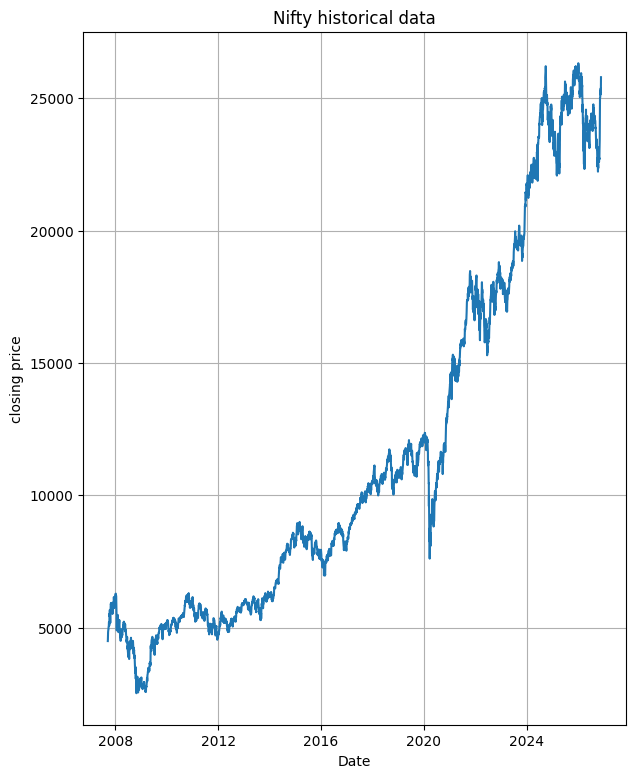

In [19]:
plt.figure(figsize=(7,9))
plt.plot(nifty.index, nifty['Close']),
plt.title('Nifty historical data'),
plt.xlabel("Date"),
plt.ylabel("closing price"),
plt.grid(True)
plt.show()

In [22]:
#daily percentage returns
nifty['Daily_return'] = nifty['Close'].pct_change()*100
print(nifty['Daily_return'].head())

Date
2007-09-17 00:00:00+05:30         NaN
2007-09-18 00:00:00+05:30    1.146926
2007-09-19 00:00:00+05:30    4.094626
2007-09-20 00:00:00+05:30    0.321187
2007-09-21 00:00:00+05:30    1.895715
Name: Daily_return, dtype: float64


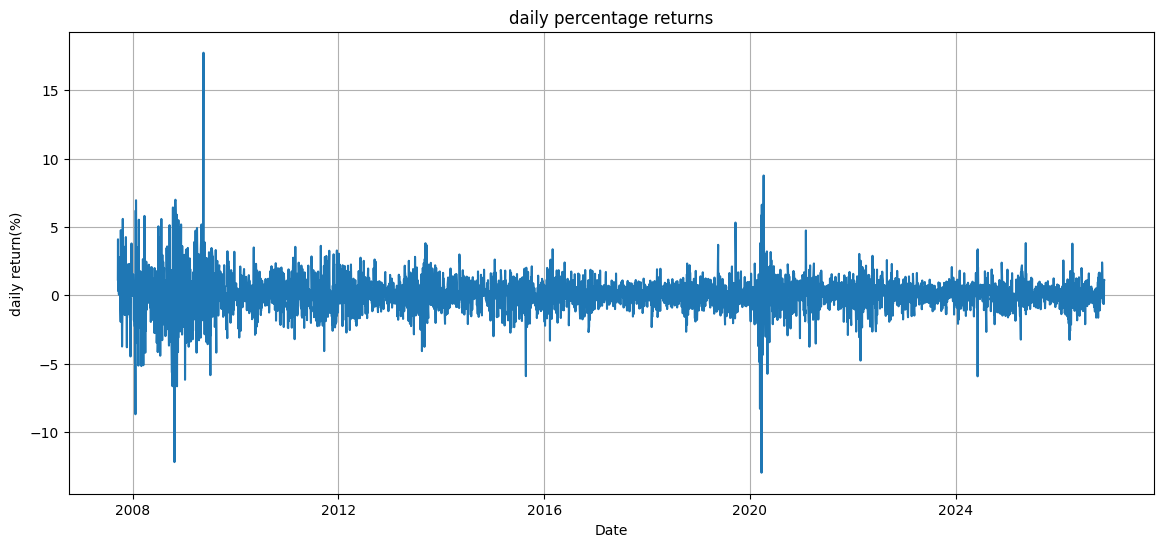

In [23]:
plt.figure(figsize=(14,6))
plt.plot(nifty.index, nifty['Daily_return'])
plt.title("daily percentage returns")
plt.xlabel('Date')
plt.ylabel('daily return(%)')
plt.grid(True)
plt.show()

In [24]:
#daily volatility

daily_volatility = nifty['Daily_return'].std()
print("daily_volatility", daily_volatility,"%")

daily_volatility 1.2904538900193414 %


In [25]:
#average return

avg_return = nifty['Daily_return'].mean()
print("Average dailty return", avg_return,"%")

Average dailty return 0.04548559425860313 %


In [26]:
#historical volatility comparison

periods = {
    '2007-2009': nifty.loc['2007':'2009'],
    '2015-2017': nifty.loc['2015':'2017'],
    '2020 -2021': nifty.loc['2020':'2021'],
    '2022-2025': nifty.loc['2022':'2025']
}

volatility_comparisson = {}

for period, data in periods.items():
  volatility_comparisson[period] = data['Daily_return'].std()

  volatility_df  = pd.DataFrame(
      list(volatility_comparisson.items()),
      columns = ['period', 'volatility']
  )

  print(volatility_df)

      period  volatility
0  2007-2009    2.469363
      period  volatility
0  2007-2009    2.469363
1  2015-2017    0.874567
       period  volatility
0   2007-2009    2.469363
1   2015-2017    0.874567
2  2020 -2021    1.560339
       period  volatility
0   2007-2009    2.469363
1   2015-2017    0.874567
2  2020 -2021    1.560339
3   2022-2025    0.852631


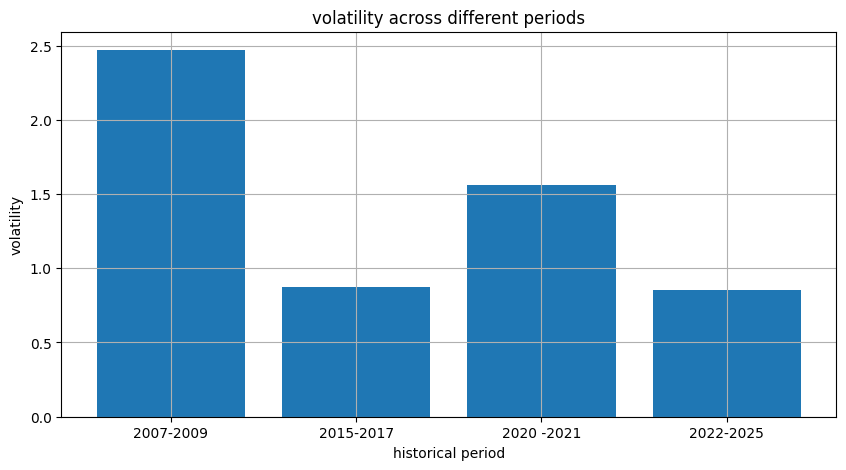

In [29]:
plt.figure(figsize=(10,5))

plt.bar(
    volatility_df['period'],
    volatility_df['volatility']
)

plt.title("volatility across different periods"),
plt.xlabel("historical period"),
plt.ylabel("volatility"),
plt.grid(True),
plt.show()

In [32]:
#feature engineering
nifty['daily_range'] = nifty['High'] - nifty['Low']
print(nifty[['Low','High','daily_range']].head())

                                   Low         High  daily_range
Date                                                            
2007-09-17 00:00:00+05:30  4482.850098  4549.049805    66.199707
2007-09-18 00:00:00+05:30  4481.549805  4551.799805    70.250000
2007-09-19 00:00:00+05:30  4550.250000  4739.000000   188.750000
2007-09-20 00:00:00+05:30  4721.149902  4760.850098    39.700195
2007-09-21 00:00:00+05:30  4733.700195  4855.700195   122.000000


In [38]:
nifty['daily_range_percentage'] = nifty['daily_range']/nifty['Close'] * 100
print(nifty['daily_range_percentage'].head(10))

Date
2007-09-17 00:00:00+05:30    1.472856
2007-09-18 00:00:00+05:30    1.545247
2007-09-19 00:00:00+05:30    3.988505
2007-09-20 00:00:00+05:30    0.836225
2007-09-21 00:00:00+05:30    2.521938
2007-09-24 00:00:00+05:30    2.108592
2007-09-25 00:00:00+05:30    1.533758
2007-09-26 00:00:00+05:30    1.022164
2007-09-27 00:00:00+05:30    1.473832
2007-09-28 00:00:00+05:30    1.181945
Name: daily_range_percentage, dtype: float64


In [39]:
print(nifty[['High','Low','Close','daily_range','daily_range_percentage']].head())

                                  High          Low        Close  daily_range  \
Date                                                                            
2007-09-17 00:00:00+05:30  4549.049805  4482.850098  4494.649902    66.199707   
2007-09-18 00:00:00+05:30  4551.799805  4481.549805  4546.200195    70.250000   
2007-09-19 00:00:00+05:30  4739.000000  4550.250000  4732.350098   188.750000   
2007-09-20 00:00:00+05:30  4760.850098  4721.149902  4747.549805    39.700195   
2007-09-21 00:00:00+05:30  4855.700195  4733.700195  4837.549805   122.000000   

                           daily_range_percentage  
Date                                               
2007-09-17 00:00:00+05:30                1.472856  
2007-09-18 00:00:00+05:30                1.545247  
2007-09-19 00:00:00+05:30                3.988505  
2007-09-20 00:00:00+05:30                0.836225  
2007-09-21 00:00:00+05:30                2.521938  


In [41]:
#moving average

nifty['SMA_7'] = nifty['Close'].rolling(window = 7).mean()
nifty['SMA_30'] = nifty['Close'].rolling(window = 30).mean()
print(nifty[['Close','SMA_7', 'SMA_30']].head(10))

                                 Close        SMA_7  SMA_30
Date                                                       
2007-09-17 00:00:00+05:30  4494.649902          NaN     NaN
2007-09-18 00:00:00+05:30  4546.200195          NaN     NaN
2007-09-19 00:00:00+05:30  4732.350098          NaN     NaN
2007-09-20 00:00:00+05:30  4747.549805          NaN     NaN
2007-09-21 00:00:00+05:30  4837.549805          NaN     NaN
2007-09-24 00:00:00+05:30  4932.200195          NaN     NaN
2007-09-25 00:00:00+05:30  4938.850098  4747.050014     NaN
2007-09-26 00:00:00+05:30  4940.500000  4810.742885     NaN
2007-09-27 00:00:00+05:30  5000.549805  4875.649972     NaN
2007-09-28 00:00:00+05:30  5021.350098  4916.935686     NaN


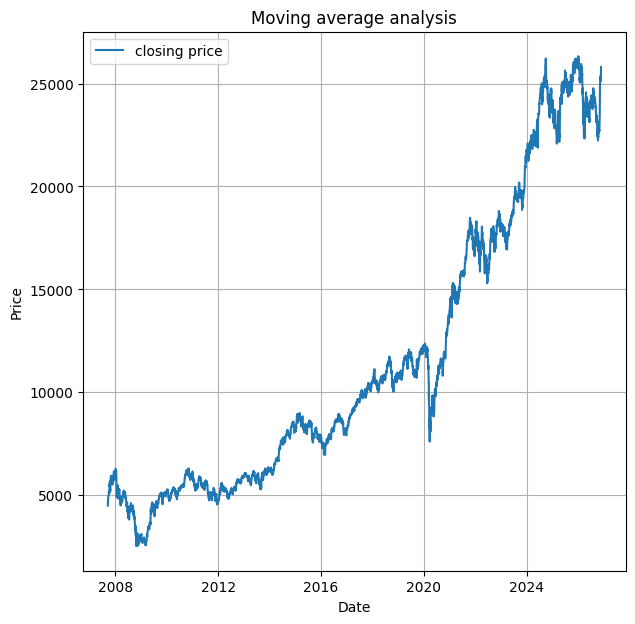

In [46]:
plt.figure(figsize=(7,7))

plt.plot(nifty.index, nifty['Close'], label = 'closing price')

plt.title("Moving average analysis")
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

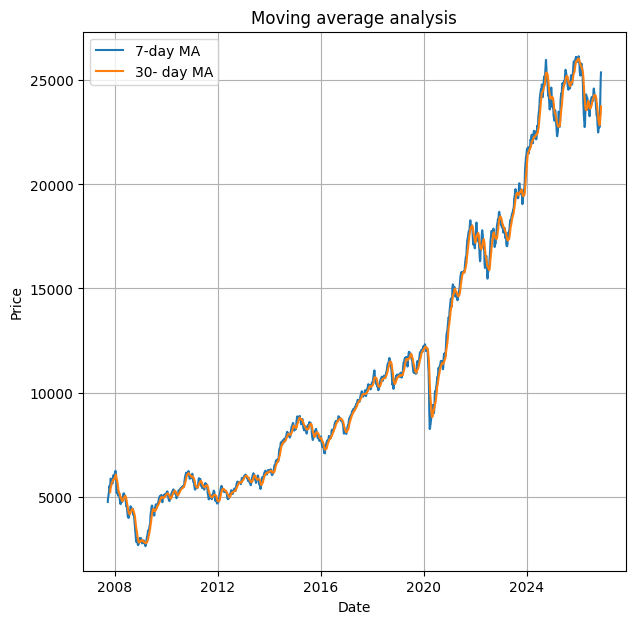

In [49]:
plt.figure(figsize=(7,7))
plt.plot(nifty.index, nifty['SMA_7'], label = "7-day MA")
plt.plot(nifty.index, nifty["SMA_30"],label= "30- day MA")
plt.title("Moving average analysis")
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()